## 1. Data Loading & Stratified Train / Validation / Test Split

In [47]:
import pandas as pd
import numpy as np
from google.colab import files
from sklearn.model_selection import StratifiedShuffleSplit

uploaded = files.upload()
df = pd.read_csv('cdi_inpatient_cohort (1).csv')
display(df.head())

Saving cdi_inpatient_cohort (1).csv to cdi_inpatient_cohort (1) (1).csv


,patient_id,age,antibiotic_days,ppi_usage,abx_spectrum,ward_type,wbc_count,serum_albumin,serum_creatinine,prior_hospitalization_6m,cdi_outcome
0,PT_0001,24.0,2.4,No,Carbapenem,General_Medical,7.41,4.28,1.32,0,0
1,PT_0002,75.0,2.0,No,Carbapenem,Oncology,6.52,2.41,0.71,0,0
2,PT_0003,66.0,3.5,No,Broad_Cephalosporin,Surgical,11.85,3.69,1.32,0,0
3,PT_0004,50.0,3.4,No,Carbapenem,ICU,8.66,3.56,1.02,0,0
4,PT_0005,50.0,4.7,No,Narrow,General_Medical,NaN,3.37,1.63,0,0


In [49]:
len(df['patient_id'])

4000

In [3]:
features = [
    'age', 'antibiotic_days', 'ppi_usage', 'abx_spectrum',
    'ward_type', 'wbc_count', 'serum_albumin', 'serum_creatinine'
]
X = df[features]
y = df['cdi_outcome']

split = StratifiedShuffleSplit(n_splits=1, test_size=0.2, random_state=42)
for temp_index, test_index in split.split(X, y):
    X_temp, X_test = X.iloc[temp_index], X.iloc[test_index]
    y_temp, y_test = y.iloc[temp_index], y.iloc[test_index]

for train_index, val_index in split.split(X_temp, y_temp):
    X_train, X_val = X_temp.iloc[train_index], X_temp.iloc[val_index]
    y_train, y_val = y_temp.iloc[train_index], y_temp.iloc[val_index]

print(f"Train: {X_train.shape}, Val: {X_val.shape}, Test: {X_test.shape}")

Train: (2560, 8), Val: (640, 8), Test: (800, 8)


## 2. Module 1: Leakage-Free Preprocessing & Stacking Ensemble Pipeline

In [4]:
import xgboost as xgb
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier, StackingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.model_selection import GridSearchCV, StratifiedKFold

ppi = ['Yes', 'No']
antibiotic_type = ['Broad_Cephalosporin', 'Narrow', 'Fluoroquinolones', 'Carbapenem']
ward_count = ['General_Medical', 'Surgical', 'ICU', 'Oncology']

cat_cols = ['ppi_usage', 'abx_spectrum']
nom_cols = ['ward_type']

cat_encoder = OrdinalEncoder(
    categories=[ppi, antibiotic_type],
    handle_unknown='use_encoded_value',
    unknown_value=np.nan
)
nom_encoder = OneHotEncoder(categories=[ward_count], handle_unknown='ignore')

preprocessor = ColumnTransformer(
    [
        ('cat', cat_encoder, cat_cols),
        ('nom', nom_encoder, nom_cols)
    ],
    remainder='passthrough'
)

base_learners = [
    ('xgb', xgb.XGBClassifier(random_state=42, n_estimators=100)),
    ('rf', RandomForestClassifier(random_state=42, n_estimators=100))
]
meta_learner = LogisticRegression(random_state=42, penalty='l2', C=1.0)

stack = StackingClassifier(
    estimators=base_learners,
    final_estimator=meta_learner,
    cv=5,
    n_jobs=-1,
    stack_method='predict_proba'
)

pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('stacking_model', stack)
])

In [6]:
param_grid = {
    'stacking_model__xgb__max_depth': [4, 5],
    'stacking_model__rf__n_estimators': [80, 100, 120],
    'stacking_model__rf__max_depth': [3, 4, 5],
    'stacking_model__final_estimator__C': [0.1, 0.5, 1.0]
}

cv_strategy = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
grid_search = GridSearchCV(pipeline, param_grid, cv=cv_strategy, scoring='roc_auc', n_jobs=-1)


In [7]:
grid_search.fit(X_train, y_train)


/usr/local/lib/python3.13/dist-packages/sklearn/compose/_column_transformer.py:1667: FutureWarning: 
The format of the columns of the 'remainder' transformer in ColumnTransformer.transformers_ will change in version 1.7 to match the format of the other transformers.
At the moment the remainder columns are stored as indices (of type int). With the same ColumnTransformer configuration, in the future they will be stored as column names (of type str).
To use the new behavior now and suppress this warning, use ColumnTransformer(force_int_remainder_cols=False).

  warnings.warn(


GridSearchCV(cv=StratifiedKFold(n_splits=5, random_state=42, shuffle=True),
             estimator=Pipeline(steps=[('preprocessor',
                                        ColumnTransformer(remainder='passthrough',
                                                          transformers=[('cat',
                                                                         OrdinalEncoder(categories=[['Yes',
                                                                                                     'No'],
                                                                                                    ['Broad_Cephalosporin',
                                                                                                     'Narrow',
                                                                                                     'Fluoroquinolones',
                                                                                                     'Carbapenem']],
                                                                                        handle_unknown='use_encoded_value',
                                                                                        unknown_value=nan),
                                                                         ['ppi_usage'...
                                                                        RandomForestClassifier(random_state=42))],
                                                           final_estimator=LogisticRegression(random_state=42),
                                                           n_jobs=-1,
                                                           stack_method='predict_proba'))]),
             n_jobs=-1,
             param_grid={'stacking_model__final_estimator__C': [0.1, 0.5, 1.0],
                         'stacking_model__rf__max_depth': [3, 4, 5],
                         'stacking_model__rf__n_estimators': [80, 100, 120],
                         'stacking_model__xgb__max_depth': [4, 5]},
             scoring='roc_auc')

In [8]:
grid_search.best_params_

{'stacking_model__final_estimator__C': 1.0,
 'stacking_model__rf__max_depth': 5,
 'stacking_model__rf__n_estimators': 100,
 'stacking_model__xgb__max_depth': 5}

In [9]:
grid_search.best_estimator_

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(remainder='passthrough',
                                   transformers=[('cat',
                                                  OrdinalEncoder(categories=[['Yes',
                                                                              'No'],
                                                                             ['Broad_Cephalosporin',
                                                                              'Narrow',
                                                                              'Fluoroquinolones',
                                                                              'Carbapenem']],
                                                                 handle_unknown='use_encoded_value',
                                                                 unknown_value=nan),
                                                  ['ppi_usage',
                                                   'abx_spectrum']),
                                                 ('nom',
                                                  OneHotEncoder(categories=[['General_Medical',
                                                                             'Surgical',
                                                                             'I...
                                                               max_cat_to_onehot=None,
                                                               max_delta_step=None,
                                                               max_depth=5,
                                                               max_leaves=None,
                                                               min_child_weight=None,
                                                               missing=nan,
                                                               monotone_constraints=None,
                                                               multi_strategy=None,
                                                               n_estimators=100,
                                                               n_jobs=None,
                                                               num_parallel_tree=None, ...)),
                                                ('rf',
                                                 RandomForestClassifier(max_depth=5,
                                                                        random_state=42))],
                                    final_estimator=LogisticRegression(random_state=42),
                                    n_jobs=-1, stack_method='predict_proba'))])

## 3. Module 2 & 3: Isotonic Probability Calibration & Clinical Cost Threshold Tuning

In [11]:
from sklearn.base import clone
from sklearn.calibration import CalibratedClassifierCV
from sklearn.model_selection import TunedThresholdClassifierCV
from sklearn.metrics import confusion_matrix, make_scorer, recall_score, precision_score, average_precision_score

# Module 2: Probability Calibration
calibrated_pipeline = CalibratedClassifierCV(grid_search.best_estimator_, cv=5, method='isotonic', n_jobs=-1)
calibrated_pipeline.fit(X_train, y_train)

# Module 3: Asymmetric Clinical Cost Threshold Optimization (FN = 5x FP)
def neg_clinical_cost(y_true, y_pred):
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred).ravel()
    return -(5 * fn + 1 * fp)

cost_scorer = make_scorer(neg_clinical_cost, response_method='predict')
tuned_model = TunedThresholdClassifierCV(
    clone(calibrated_pipeline), scoring=cost_scorer, cv=5, n_jobs=-1
).fit(X_train, y_train)

print(f"Optimal Clinical Decision Threshold: {tuned_model.best_threshold_:.4f}")

Optimal Clinical Decision Threshold: 0.2027


In [12]:
# Evaluate Validation & Test Performance (using continuous probabilities for PR-AUC)
y_val_prob = calibrated_pipeline.predict_proba(X_val)[:, 1]
y_val_pred = tuned_model.predict(X_val)

y_test_prob = calibrated_pipeline.predict_proba(X_test)[:, 1]
y_test_pred = tuned_model.predict(X_test)

metrics_summary = pd.DataFrame({
    'Metric': ['Recall', 'Precision', 'PR-AUC (Average Precision)'],
    'Validation Score': [
        recall_score(y_val, y_val_pred),
        precision_score(y_val, y_val_pred),
        average_precision_score(y_val, y_val_prob)
    ],
    'Test Score': [
        recall_score(y_test, y_test_pred),
        precision_score(y_test, y_test_pred),
        average_precision_score(y_test, y_test_prob)
    ]
})
display(metrics_summary)

,Metric,Validation Score,Test Score
0,Recall,0.686957,0.643357
1,Precision,0.369159,0.333333
2,PR-AUC (Average Precision),0.429359,0.390727


In [13]:
! pip install shap

In [14]:
import shap

In [61]:
import shap
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Helper so SHAP keeps exact column names & numeric types when testing combinations
num_cols = ['age', 'antibiotic_days', 'wbc_count', 'serum_albumin', 'serum_creatinine']
def predict_cdi_prob(X_arr):
    df_tmp = pd.DataFrame(X_arr, columns=X_train.columns)
    for col in num_cols:
        df_tmp[col] = pd.to_numeric(df_tmp[col])
    return tuned_model.predict_proba(df_tmp)[:, 1]

# Create background dataset of 50 samples
background = shap.utils.sample(X_train, 50, random_state=42)

# Use KernelExplainer to safely process both string and numeric features without math errors
explainer = shap.KernelExplainer(predict_cdi_prob, background)
shap_values_raw = explainer.shap_values(X_test)

# Wrap results in a structured Explanation object for plotting support
shap_values = shap.Explanation(
    values=shap_values_raw,
    base_values=np.repeat(explainer.expected_value, len(X_test)),
    data=X_test,
    feature_names=X_test.columns.tolist()
)

  0%|          | 0/800 [00:00<?, ?it/s]

In [62]:
importance_table = pd.DataFrame({
    'Feature': X_train.columns,
    'Mean_Abs_SHAP_Impact': abs(shap_values.values).mean(axis=0)
}).sort_values('Mean_Abs_SHAP_Impact', ascending=False).reset_index(drop=True)

display(importance_table)

,Feature,Mean_Abs_SHAP_Impact
0,antibiotic_days,0.070997
1,age,0.062214
2,serum_albumin,0.047381
3,wbc_count,0.021050
4,abx_spectrum,0.019683
5,ward_type,0.018786
6,serum_creatinine,0.015600
7,ppi_usage,0.014719


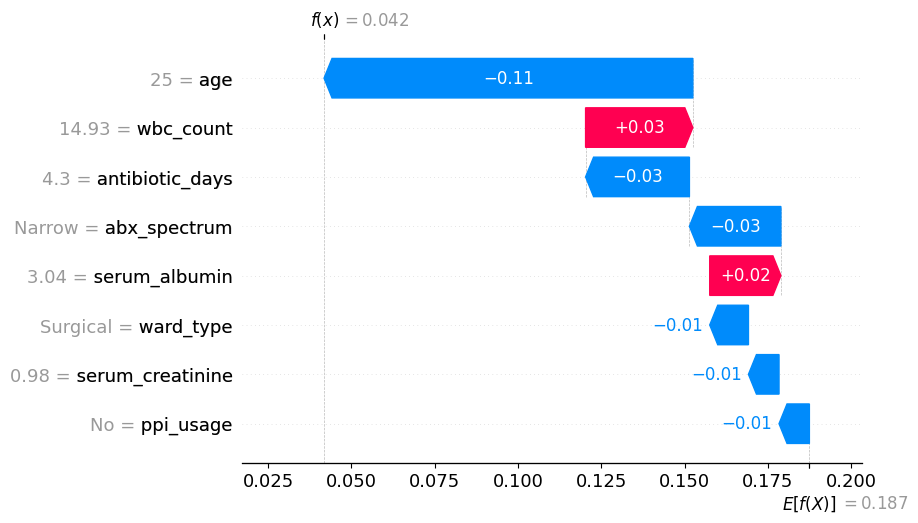

  0%|          | 0/1 [00:00<?, ?it/s]

Predicted Risk: 0.641 | Threshold: 0.203


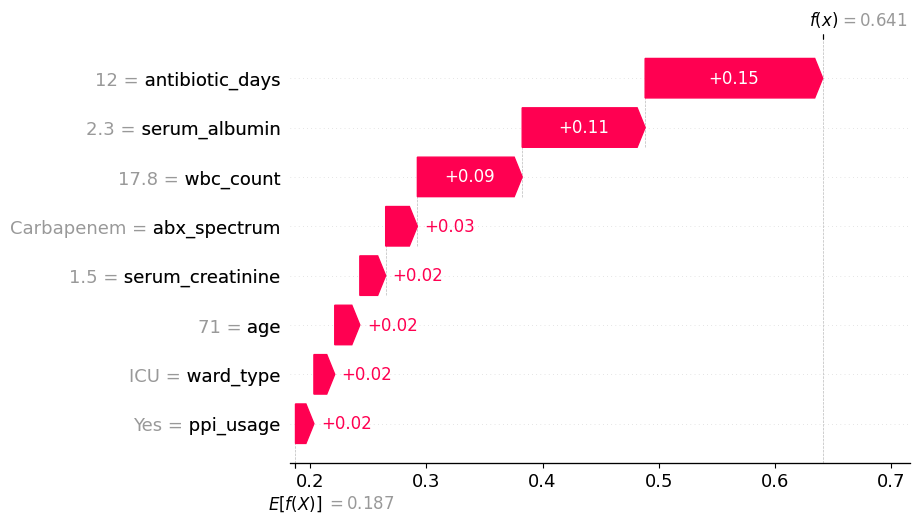

In [63]:
# --- A) Waterfall for Patient #0 in X_test ---
shap.plots.waterfall(shap_values[0])

# --- B) Waterfall for a Manually Entered Patient ---
manual_patient = pd.DataFrame([{
    'age': 71,
    'antibiotic_days': 12,
    'ppi_usage': 'Yes',
    'abx_spectrum': 'Carbapenem',
    'ward_type': 'ICU',
    'wbc_count': 17.8,
    'serum_albumin': 2.3,
    'serum_creatinine': 1.5
}])

manual_shap = explainer(manual_patient)
print(f"Predicted Risk: {tuned_model.predict_proba(manual_patient)[0, 1]:.3f} | Threshold: {tuned_model.best_threshold_:.3f}")
shap.plots.waterfall(manual_shap[0])

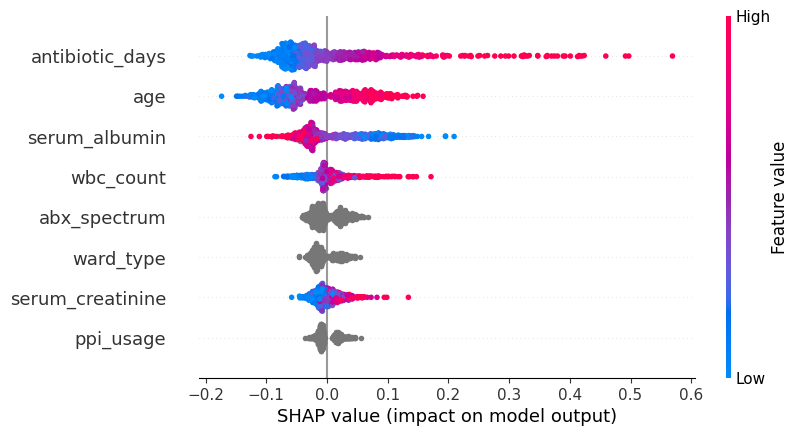

In [64]:
shap.plots.beeswarm(shap_values)